# Dana’s Bakery Order Graph
A deterministic bakery order processor built with LangGraph. Each invocation reads the fixed stock table and does not modify it.

In [1]:
!pip install -q langgraph

## Data
Menu, stock, and business rules are constants. Stock is treated as read-only by every graph run.

In [2]:
from typing import Annotated, TypedDict
import operator
from langgraph.graph import StateGraph, START, END

PRICES = {"challah": 18, "babka": 45, "rugelach": 30, "sourdough": 25}
STOCK = {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}
SUBSTITUTION_CHAIN = {"babka": "rugelach", "rugelach": "sourdough", "sourdough": "challah"}
MAX_SUBSTITUTIONS = 2
DISCOUNT_RATE = 0.15
DISCOUNT_THRESHOLD = 150
NO_DISCOUNT_DAY = "friday"
DELIVERY_CITY_NAMES = {"jerusalem", "ירושלים"}
DELIVERY_FEE = 20
VALID_DAYS = {"sunday", "monday", "tuesday", "wednesday", "thursday", "friday", "saturday"}
DISPLAY_NAMES = {  # (singular, plural) for customer messages
    "challah": ("challah", "challahs"),
    "babka": ("babka", "babkas"),
    "rugelach": ("box of rugelach", "boxes of rugelach"),
    "sourdough": ("sourdough loaf", "sourdough loaves"),
}


## State
The `steps` reducer appends one entry from each node in execution order.

In [3]:
class OrderState(TypedDict, total=False):
    item: str | None
    quantity: int
    day: str
    city: str | None
    requested_item: str
    attempts: int
    reject_reason: str | None
    subtotal: float
    discount: float
    delivery_fee: float
    delivery_note: str | None
    status: str
    delivery: str
    total: float
    message: str
    steps: Annotated[list[str], operator.add]


## Nodes

In [4]:
def validate(state: OrderState) -> dict:
    """Normalize and validate the requested product, quantity, and day."""
    raw_item = state.get("item")
    item = raw_item.strip().lower() if isinstance(raw_item, str) else ""
    raw_day = state.get("day")
    day = raw_day.strip().lower() if isinstance(raw_day, str) else ""
    quantity = state.get("quantity")
    valid = item in PRICES and isinstance(quantity, int) and not isinstance(quantity, bool) and quantity > 0 and day in VALID_DAYS
    update = {"item": item if item else None, "day": day, "requested_item": item, "attempts": 0, "reject_reason": None if valid else "invalid", "steps": ["validate: ok" if valid else "validate: invalid order"]}
    return update


def check_stock(state: OrderState) -> dict:
    """Record whether the requested product can fill the full order."""
    item, quantity = state["item"], state["quantity"]
    available = STOCK[item] >= quantity
    return {"steps": [f"check_stock: {item} x{quantity} {'in stock' if available else 'not in stock'}"]}


def substitute(state: OrderState) -> dict:
    """Try the next product in the substitution chain, within the attempt limit."""
    item, quantity = state["item"], state["quantity"]
    next_item = SUBSTITUTION_CHAIN.get(item)
    attempts = state.get("attempts", 0)
    if next_item is None:
        return {"reject_reason": "out_of_stock", "steps": [f"substitute: no substitute for {item} (out of stock)"]}
    attempts += 1
    in_stock = STOCK[next_item] >= quantity
    reason = None if in_stock or (attempts < MAX_SUBSTITUTIONS and next_item in SUBSTITUTION_CHAIN) else "out_of_stock"
    return {"item": next_item, "attempts": attempts, "reject_reason": reason, "steps": [f"substitute #{attempts}: {item} -> {next_item} ({'in stock' if in_stock else 'not in stock'})"]}


def pricing(state: OrderState) -> dict:
    """Calculate goods subtotal and any eligible goods discount."""
    subtotal = PRICES[state["item"]] * state["quantity"]
    discount = subtotal * DISCOUNT_RATE if subtotal > DISCOUNT_THRESHOLD and state["day"] != NO_DISCOUNT_DAY else 0.0
    return {"subtotal": float(subtotal), "discount": float(discount), "steps": [f"pricing: subtotal {subtotal}, discount {discount:g}"]}


def delivery(state: OrderState) -> dict:
    """Choose delivery or pickup and calculate the final amount."""
    city = state.get("city")
    normalized_city = city.strip().lower() if isinstance(city, str) else ""
    note = None
    if not normalized_city:
        mode, fee = "pickup", 0
        step = "delivery: pickup, fee 0"
    elif normalized_city in DELIVERY_CITY_NAMES:
        mode, fee = "delivery", DELIVERY_FEE
        step = f"delivery: delivery to {city.strip()}, fee {fee}"
    else:
        mode, fee = "pickup", 0
        note = "We don’t deliver outside Jerusalem, so we’ve kept your order as pickup."
        step = "delivery: outside Jerusalem, switched to pickup, fee 0"
    total = round(state["subtotal"] - state["discount"] + fee, 2)
    return {"delivery": mode, "delivery_fee": float(fee), "delivery_note": note, "total": total, "steps": [step]}


def compose_message(state: OrderState) -> dict:
    """Write a warm customer reply using display names and Python templates."""
    item, quantity = state["item"], state["quantity"]
    display_name = DISPLAY_NAMES[item][0 if quantity == 1 else 1]
    parts = [f"Thanks for your order! We’re happy to prepare {quantity} {display_name} for you."]
    if item != state["requested_item"]:
        original_name = DISPLAY_NAMES[state["requested_item"]][0]
        replacement_name = DISPLAY_NAMES[item][0]
        parts.insert(0, f"We’re sorry, your original choice of {original_name} was out of stock, so we substituted {replacement_name} at {PRICES[item]} ILS per unit.")
    if state["discount"]:
        parts.append(f"Your goods discount is {state['discount']:g} ILS.")
    if state.get("delivery_note"):
        parts.append(state["delivery_note"])
    parts.append(f"Your total is {state['total']:g} ILS. See you soon!")
    return {"status": "accepted", "message": " ".join(parts), "steps": ["compose_message: accepted"]}


def reject(state: OrderState) -> dict:
    """Cancel an invalid or unfulfillable order with a polite explanation."""
    reason = state.get("reject_reason")
    if reason == "invalid":
        message = "Sorry, we couldn’t understand your order. Please check the product, quantity, and day and try again."
        step = "reject: invalid order"
    else:
        requested = state.get("requested_item")
        requested_name = DISPLAY_NAMES[requested][0] if requested in DISPLAY_NAMES else "requested product"
        message = f"We’re sorry, {requested_name} and our suggested alternatives are out of stock, so your order has been cancelled."
        step = "reject: out of stock"
    return {"status": "rejected", "item": None, "delivery": "pickup", "total": 0, "message": message, "steps": [step]}


## Routers
Named routers keep all conditional transitions explicit. The substitution node sets the rejection reason before the router sends an order to `reject`.

In [5]:
def route_after_validate(state: OrderState) -> str:
    """Choose rejection or stock check after validation."""
    return "reject" if state.get("reject_reason") == "invalid" else "check_stock"


def route_after_stock(state: OrderState) -> str:
    """Send available orders to pricing and others to substitution."""
    return "pricing" if STOCK[state["item"]] >= state["quantity"] else "substitute"


def route_after_substitute(state: OrderState) -> str:
    """Continue with a stocked substitute, try another, or reject."""
    if STOCK[state["item"]] >= state["quantity"]:
        return "pricing"
    if state.get("reject_reason") == "out_of_stock":
        return "reject"
    return "substitute"


## Graph
The graph returns the complete state, including all six customer-facing output keys.

In [6]:
builder = StateGraph(OrderState)
for node in (validate, check_stock, substitute, pricing, delivery, compose_message, reject):
    builder.add_node(node.__name__, node)
builder.add_edge(START, "validate")
builder.add_conditional_edges("validate", route_after_validate, {"reject": "reject", "check_stock": "check_stock"})
builder.add_conditional_edges("check_stock", route_after_stock, {"pricing": "pricing", "substitute": "substitute"})
builder.add_conditional_edges("substitute", route_after_substitute, {"pricing": "pricing", "substitute": "substitute", "reject": "reject"})
builder.add_edge("pricing", "delivery")
builder.add_edge("delivery", "compose_message")
builder.add_edge("compose_message", END)
builder.add_edge("reject", END)
graph = builder.compile()


## Drawing

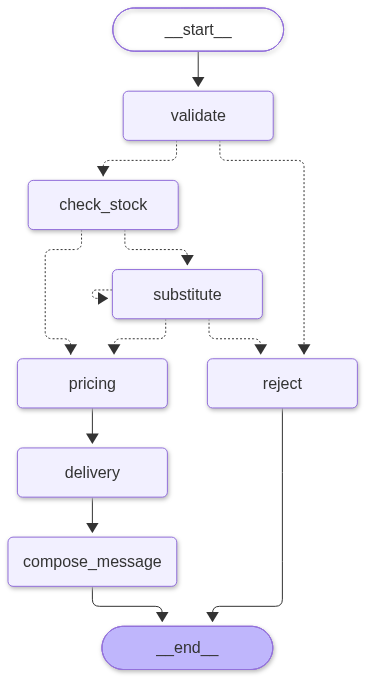

In [7]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

## Tests
Each example has its own titled cell and checks the required outcome fields.

In [8]:
def run(order):
    """Invoke the graph, print the six requested outputs, and return the result."""
    result = graph.invoke(order)
    for key in ("status", "item", "delivery", "total", "message"):
        print(f"{key}: {result.get(key)}")
    print("steps:")
    for step in result.get("steps", []):
        print(f"- {step}")
    return result

### 1. Challah in stock with Jerusalem delivery

In [9]:
result = run({'item': 'challah', 'quantity': 3, 'day': 'Thursday', 'city': 'Jerusalem'})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('accepted', 'challah', 'delivery', 74)

status: accepted
item: challah
delivery: delivery
total: 74.0
message: Thanks for your order! We’re happy to prepare 3 challahs for you. Your total is 74 ILS. See you soon!
steps:
- validate: ok
- check_stock: challah x3 in stock
- pricing: subtotal 54, discount 0
- delivery: delivery to Jerusalem, fee 20
- compose_message: accepted


### 2. Challah discount with pickup

In [10]:
result = run({'item': 'challah', 'quantity': 10, 'day': 'Thursday', 'city': ''})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('accepted', 'challah', 'pickup', 153)

status: accepted
item: challah
delivery: pickup
total: 153.0
message: Thanks for your order! We’re happy to prepare 10 challahs for you. Your goods discount is 27 ILS. Your total is 153 ILS. See you soon!
steps:
- validate: ok
- check_stock: challah x10 in stock
- pricing: subtotal 180, discount 27
- delivery: pickup, fee 0
- compose_message: accepted


### 3. Friday order has no discount

In [11]:
result = run({'item': 'challah', 'quantity': 10, 'day': 'Friday', 'city': 'Jerusalem'})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('accepted', 'challah', 'delivery', 200)

status: accepted
item: challah
delivery: delivery
total: 200.0
message: Thanks for your order! We’re happy to prepare 10 challahs for you. Your total is 200 ILS. See you soon!
steps:
- validate: ok
- check_stock: challah x10 in stock
- pricing: subtotal 180, discount 0
- delivery: delivery to Jerusalem, fee 20
- compose_message: accepted


### 4. Discount applies to goods only

In [12]:
result = run({'item': 'challah', 'quantity': 9, 'day': 'Thursday', 'city': 'jerusalem '})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('accepted', 'challah', 'delivery', 157.7)

status: accepted
item: challah
delivery: delivery
total: 157.7
message: Thanks for your order! We’re happy to prepare 9 challahs for you. Your goods discount is 24.3 ILS. Your total is 157.7 ILS. See you soon!
steps:
- validate: ok
- check_stock: challah x9 in stock
- pricing: subtotal 162, discount 24.3
- delivery: delivery to jerusalem, fee 20
- compose_message: accepted


### 5. Babka substitutes to rugelach

In [13]:
result = run({'item': 'babka', 'quantity': 2, 'day': 'Thursday', 'city': 'Jerusalem'})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('accepted', 'rugelach', 'delivery', 80)

status: accepted
item: rugelach
delivery: delivery
total: 80.0
message: We’re sorry, your original choice of babka was out of stock, so we substituted box of rugelach at 30 ILS per unit. Thanks for your order! We’re happy to prepare 2 boxes of rugelach for you. Your total is 80 ILS. See you soon!
steps:
- validate: ok
- check_stock: babka x2 not in stock
- substitute #1: babka -> rugelach (in stock)
- pricing: subtotal 60, discount 0
- delivery: delivery to Jerusalem, fee 20
- compose_message: accepted


### 6. Two substitutions and outside-city pickup

In [14]:
result = run({'item': 'babka', 'quantity': 4, 'day': 'Sunday', 'city': 'Tel Aviv'})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('accepted', 'sourdough', 'pickup', 100)

status: accepted
item: sourdough
delivery: pickup
total: 100.0
message: We’re sorry, your original choice of babka was out of stock, so we substituted sourdough loaf at 25 ILS per unit. Thanks for your order! We’re happy to prepare 4 sourdough loaves for you. We don’t deliver outside Jerusalem, so we’ve kept your order as pickup. Your total is 100 ILS. See you soon!
steps:
- validate: ok
- check_stock: babka x4 not in stock
- substitute #1: babka -> rugelach (not in stock)
- substitute #2: rugelach -> sourdough (in stock)
- pricing: subtotal 100, discount 0
- delivery: outside Jerusalem, switched to pickup, fee 0
- compose_message: accepted


### 7. Two substitutions ending at challah

In [15]:
result = run({'item': 'rugelach', 'quantity': 5, 'day': 'Monday', 'city': 'ירושלים'})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('accepted', 'challah', 'delivery', 110)

status: accepted
item: challah
delivery: delivery
total: 110.0
message: We’re sorry, your original choice of box of rugelach was out of stock, so we substituted challah at 18 ILS per unit. Thanks for your order! We’re happy to prepare 5 challahs for you. Your total is 110 ILS. See you soon!
steps:
- validate: ok
- check_stock: rugelach x5 not in stock
- substitute #1: rugelach -> sourdough (not in stock)
- substitute #2: sourdough -> challah (in stock)
- pricing: subtotal 90, discount 0
- delivery: delivery to ירושלים, fee 20
- compose_message: accepted


### 8. Failed substitutions cancel order

In [16]:
result = run({'item': 'babka', 'quantity': 5, 'day': 'Tuesday', 'city': 'Jerusalem'})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('rejected', None, 'pickup', 0)

status: rejected
item: None
delivery: pickup
total: 0
message: We’re sorry, babka and our suggested alternatives are out of stock, so your order has been cancelled.
steps:
- validate: ok
- check_stock: babka x5 not in stock
- substitute #1: babka -> rugelach (not in stock)
- substitute #2: rugelach -> sourdough (not in stock)
- reject: out of stock


### 9. Challah out of stock with no substitute

In [17]:
result = run({'item': 'challah', 'quantity': 11, 'day': 'Wednesday', 'city': ''})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('rejected', None, 'pickup', 0)

status: rejected
item: None
delivery: pickup
total: 0
message: We’re sorry, challah and our suggested alternatives are out of stock, so your order has been cancelled.
steps:
- validate: ok
- check_stock: challah x11 not in stock
- substitute: no substitute for challah (out of stock)
- reject: out of stock


### 10. Unknown pizza product

In [18]:
result = run({'item': 'pizza', 'quantity': 1, 'day': 'Sunday', 'city': ''})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('rejected', None, 'pickup', 0)

status: rejected
item: None
delivery: pickup
total: 0
message: Sorry, we couldn’t understand your order. Please check the product, quantity, and day and try again.
steps:
- validate: invalid order
- reject: invalid order


### 11. Croissant is not on the menu

In [19]:
result = run({'item': 'croissant', 'quantity': 2, 'day': 'Sunday', 'city': ''})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('rejected', None, 'pickup', 0)

status: rejected
item: None
delivery: pickup
total: 0
message: Sorry, we couldn’t understand your order. Please check the product, quantity, and day and try again.
steps:
- validate: invalid order
- reject: invalid order


### 12. Zero quantity is invalid

In [20]:
result = run({'item': 'challah', 'quantity': 0, 'day': 'Sunday', 'city': ''})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('rejected', None, 'pickup', 0)

status: rejected
item: None
delivery: pickup
total: 0
message: Sorry, we couldn’t understand your order. Please check the product, quantity, and day and try again.
steps:
- validate: invalid order
- reject: invalid order


### 13. Negative quantity is invalid

In [21]:
result = run({'item': 'babka', 'quantity': -2, 'day': 'Sunday', 'city': ''})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('rejected', None, 'pickup', 0)

status: rejected
item: None
delivery: pickup
total: 0
message: Sorry, we couldn’t understand your order. Please check the product, quantity, and day and try again.
steps:
- validate: invalid order
- reject: invalid order


### 14. Invalid weekday is rejected

In [22]:
result = run({'item': 'challah', 'quantity': 2, 'day': 'Funday', 'city': ''})
assert (result["status"], result["item"], result["delivery"], result["total"]) == ('rejected', None, 'pickup', 0)

status: rejected
item: None
delivery: pickup
total: 0
message: Sorry, we couldn’t understand your order. Please check the product, quantity, and day and try again.
steps:
- validate: invalid order
- reject: invalid order


### All results include the six required output keys

In [23]:
test_orders = [
    {"item": "challah", "quantity": 3, "day": "Thursday", "city": "Jerusalem"},
    {"item": "challah", "quantity": 10, "day": "Thursday", "city": ""},
    {"item": "challah", "quantity": 10, "day": "Friday", "city": "Jerusalem"},
    {"item": "challah", "quantity": 9, "day": "Thursday", "city": "jerusalem "},
    {"item": "babka", "quantity": 2, "day": "Thursday", "city": "Jerusalem"},
    {"item": "babka", "quantity": 4, "day": "Sunday", "city": "Tel Aviv"},
    {"item": "rugelach", "quantity": 5, "day": "Monday", "city": "ירושלים"},
    {"item": "babka", "quantity": 5, "day": "Tuesday", "city": "Jerusalem"},
    {"item": "challah", "quantity": 11, "day": "Wednesday", "city": ""},
    {"item": "pizza", "quantity": 1, "day": "Sunday", "city": ""},
    {"item": "croissant", "quantity": 2, "day": "Sunday", "city": ""},
    {"item": "challah", "quantity": 0, "day": "Sunday", "city": ""},
    {"item": "babka", "quantity": -2, "day": "Sunday", "city": ""},
    {"item": "challah", "quantity": 2, "day": "Funday", "city": ""},
]
required_keys = {"status", "item", "delivery", "total", "message", "steps"}
all_results = [graph.invoke(order) for order in test_orders]
assert all(required_keys <= result.keys() for result in all_results)
print(f"All {len(all_results)} orders returned all six output keys.")

All 14 orders returned all six output keys.
